# K-Nearest Neighbours (KNN) Algorithm

This notebook covers mathematics, classification, regression, feature scaling, weighted KNN, visualisation, exercises and solutions.

## Learning Outcomes
- Explain feature vectors and distance metrics
- Calculate Euclidean distance manually
- Perform KNN classification and regression
- Understand the effect of k
- Apply feature scaling
- Implement KNN using scikit-learn

## 1. Mathematics of KNN

A feature vector represents an observation as numerical values.

Euclidean Distance:

$d(x,y)=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}$

### Worked Example
Training point A=(2,3), Query=(5,7)

$d=\sqrt{(5-2)^2+(7-3)^2}=\sqrt{9+16}=\sqrt{25}=5$

### Explanation
This code verifies the manual calculation above using **NumPy**.
- We define points `A` and `Q` as NumPy arrays.
- We use `np.linalg.norm(Q - A)` to calculate the vector magnitude (Euclidean distance) between the two coordinates.

In [1]:
import numpy as np
A=np.array([2,3])
Q=np.array([5,7])
print(np.linalg.norm(Q-A))

5.0


## 2. Manual KNN Classification

### Explanation
This cell implements a manual K-Nearest Neighbours classifier:
1. **Data Creation**: We construct a small `pandas.DataFrame` representing training points with classes (`Red` or `Blue`).
2. **Distance Calculation**: We compute the Euclidean distance from a query point `(3,3)` to every row in the dataset using a list comprehension and `np.linalg.norm`.
3. **Sorting**: We sort the DataFrame by the computed distances.
4. **Voting**: We select the top 3 nearest neighbours and use Python's `Counter` to determine the majority class.

In [2]:
import pandas as pd
from collections import Counter

data=pd.DataFrame({
"x":[1,2,4,5,3],
"y":[1,2,4,5,1],
"class":["Red","Red","Blue","Blue","Red"]})
query=np.array([3,3])
data["distance"]=[np.linalg.norm(query-np.array([r.x,r.y])) for _,r in data.iterrows()]
data=data.sort_values("distance")
display(data)
nearest=data.head(3)
print("Prediction:",Counter(nearest["class"]).most_common(1)[0][0])

,x,y,class,distance
1,2,2,Red,1.414214
2,4,4,Blue,1.414214
4,3,1,Red,2.000000
0,1,1,Red,2.828427
3,5,5,Blue,2.828427


Prediction: Red


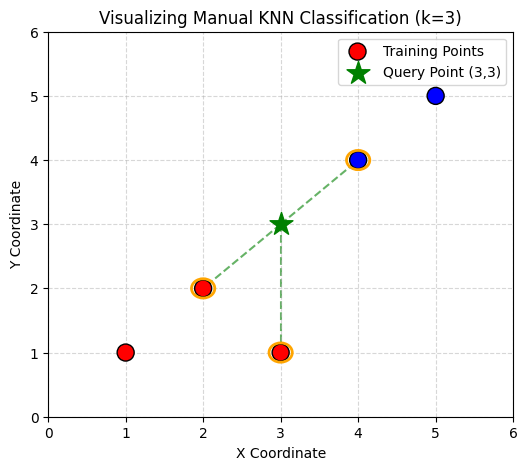

In [9]:
import matplotlib.pyplot as plt

# Create a plot to visualize the training points and the query point
plt.figure(figsize=(6, 5))

# Plot the training data points with their corresponding class colors
colors = {'Red': 'red', 'Blue': 'blue'}
plt.scatter(data['x'], data['y'], c=data['class'].map(colors), s=150, label='Training Points', edgecolors='black', zorder=2)

# Plot the query point
plt.scatter(query[0], query[1], c='green', marker='*', s=300, label='Query Point (3,3)', zorder=3)

# Circle the nearest 3 neighbours
for idx, row in nearest.iterrows():
    plt.plot([query[0], row['x']], [query[1], row['y']], 'g--', alpha=0.6, zorder=1)
    plt.gca().add_patch(plt.Circle((row['x'], row['y']), 0.15, color='orange', fill=False, lw=2, zorder=3))

plt.title("Visualizing Manual KNN Classification (k=3)")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xlim(0, 6)
plt.ylim(0, 6)
plt.show()

### Majority Voting
The class receiving the most votes among the k closest neighbours becomes the prediction.

## 3. Choosing k

### Explanation
Here, we analyze the impact of the hyperparameter $k$ on performance:
1. We load the standard **Iris flower dataset**.
2. We split it into training ($70\%$) and testing ($30\%$) sets.
3. We loop through odd values of $k$ from $1$ to $13$, fit a `KNeighborsClassifier` on the training data, and compute the evaluation accuracy on the test set.

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X,y=load_iris(return_X_y=True)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
k_values = list(range(1, 31))
for k in k_values:
    model=KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train,y_train)
    print(k, accuracy_score(y_test,model.predict(X_test)))

1 1.0
2 1.0
3 1.0
4 1.0
5 1.0
6 1.0
7 1.0
8 1.0
9 1.0
10 1.0
11 1.0
12 1.0
13 1.0
14 1.0
15 1.0
16 1.0
17 1.0
18 1.0
19 1.0
20 1.0
21 1.0
22 1.0
23 1.0
24 1.0
25 1.0
26 1.0
27 1.0
28 1.0
29 1.0
30 1.0


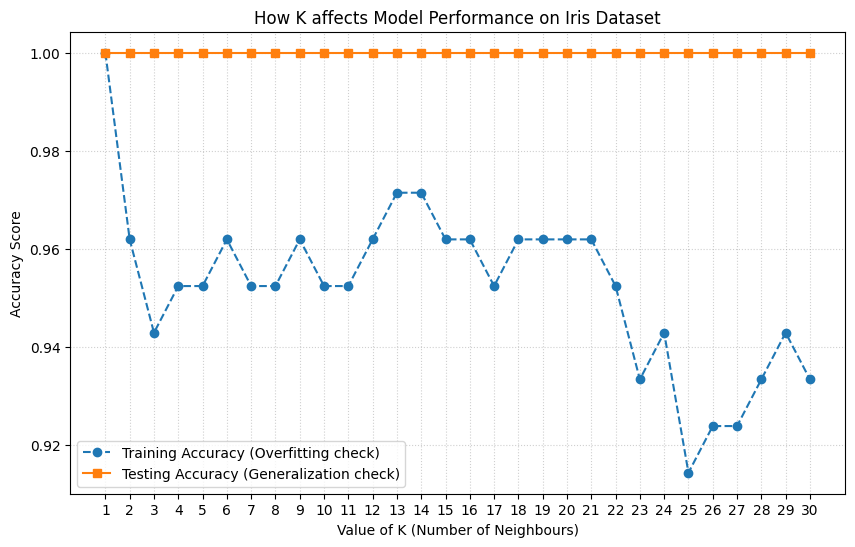

In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 1. Load the Iris dataset and split into Training (70%) and Testing (30%)
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=42)

# 2. Evaluate performance over a wide range of K values (from 1 to 30)
k_values = list(range(1, 31))
train_accuracies = []
test_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    # Calculate score on training data (helps identify overfitting)
    train_accuracies.append(knn.score(X_train, y_train))
    # Calculate score on validation data (measures generalization)
    test_accuracies.append(knn.score(X_test, y_test))

# 3. Plot the training and testing curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_accuracies, label='Training Accuracy (Overfitting check)', marker='o', linestyle='--')
plt.plot(k_values, test_accuracies, label='Testing Accuracy (Generalization check)', marker='s')
plt.xlabel('Value of K (Number of Neighbours)')
plt.ylabel('Accuracy Score')
plt.title('How K affects Model Performance on Iris Dataset')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(k_values)
plt.show()

# --- Quick Explanation of the Relationship ---
# - Low K (e.g. k=1): Extremely flexible decision boundary. Training accuracy is 100%, but highly susceptible to noise.
# - High K (e.g. k=30): Smoother decision boundary. Keeps high generalization because Iris classes are distinct,
#   but training accuracy drops as it votes using a larger neighborhood size.

### Discussion
- Small k may overfit and be sensitive to noise.
- Large k may underfit and oversmooth decision boundaries.

## 4. Weighted KNN
Closer neighbours often provide more reliable information.

Weight = 1/distance

### Explanation
This code demonstrates how to initialize a **Weighted KNN** classifier in scikit-learn.
- By passing `weights="distance"`, the algorithm assigns higher voting importance to closer neighbours ($weight \propto 1/distance$) instead of giving all $k$ neighbours an equal vote.

In [4]:
from sklearn.neighbors import KNeighborsClassifier
weighted_model = KNeighborsClassifier(n_neighbors=5,weights="distance")
weighted_model

KNeighborsClassifier(weights='distance')

## 5. Feature Scaling

### Explanation
This cell demonstrates the visual and numerical impact of standardizing feature scales:
- We create a dataset with two features: `Age` (small scale) and `Income` (very large scale).
- We use scikit-learn's `StandardScaler` to perform standardisation, ensuring both features have a mean ($\mu$) of $0$ and a standard deviation ($\sigma$) of $1$ so that `Income` doesn't dominate distance calculations.

In [5]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

df=pd.DataFrame({"Age":[18,25,30,40],"Income":[15000,45000,70000,120000]})
print("Original")
print(df)
scaled=StandardScaler().fit_transform(df)
print("Scaled")
print(scaled)

Original
   Age  Income
0   18   15000
1   25   45000
2   30   70000
3   40  120000
Scaled
[[-1.27937728 -1.23418262]
 [-0.40565621 -0.45469886]
 [ 0.21843027  0.19487094]
 [ 1.46660323  1.49401055]]


### Standardisation Formula

$z=(x-\mu)/\sigma$

## 6. Visualising Neighbours

### Explanation
This code generates and visualizes synthetic dataset clusters:
- We generate a toy classification dataset using `make_blobs`.
- We plot the 2D feature vectors with `matplotlib.pyplot` and colour-code each point by its true cluster class label.

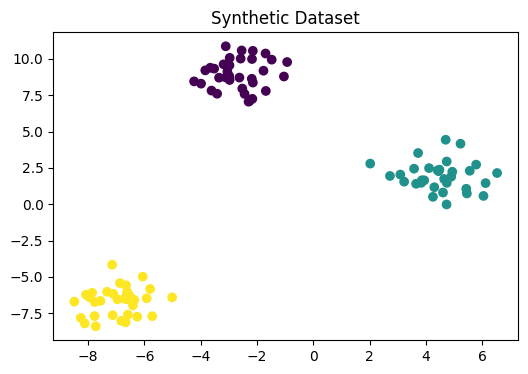

In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
X,y=make_blobs(n_samples=100,centers=3,random_state=42)
plt.figure(figsize=(6,4))
plt.scatter(X[:,0],X[:,1],c=y,cmap="viridis")
plt.title("Synthetic Dataset")
plt.show()

## 7. KNN using the Iris Dataset

### Explanation
This cell shows an end-to-end evaluation pipeline using the Iris dataset:
- We split the data into training and test sets, and train a `KNeighborsClassifier` with $k=5$.
- We use a **Confusion Matrix** to show where classification mistakes were made (if any) and a **Classification Report** to calculate Precision, Recall, and F1-score for each target class.

In [7]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import train_test_split

iris=load_iris()
X_train,X_test,y_train,y_test=train_test_split(iris.data,iris.target,test_size=0.3,random_state=42)
model=KNeighborsClassifier(n_neighbors=5)
model.fit(X_train,y_train)
pred=model.predict(X_test)
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



## 8. KNN Regression

### Explanation
This cell demonstrates KNN for a regression task (predicting continuous numerical values):
- We fit a `KNeighborsRegressor` with $k=2$ on a 1D dataset.
- To predict the value for query point `[[3.5]]`, the model identifies the two nearest training samples ($x=3$ and $x=4$) and averages their targets ($28$ and $39$) to get `33.5`.

In [8]:
from sklearn.neighbors import KNeighborsRegressor
import numpy as np
X=np.array([[1],[2],[3],[4],[5],[6]])
y=np.array([10,20,28,39,50,61])
reg=KNeighborsRegressor(n_neighbors=2)
reg.fit(X,y)
print(reg.predict([[3.5]]))

[33.5]


## Exercise 1
Calculate the Euclidean distance between (1,2) and (4,6).

## Exercise 2
For k=1 and k=15, explain the likely effect on model behaviour.

## Exercise 3
Why is feature scaling important for KNN?

## Exercise 4
Use the Iris dataset and compare k=3,5,7.

## Exercise 5
Convert the classifier into a weighted KNN classifier and compare results.

## Solutions

1. Distance=5
2. Small k can overfit; large k can underfit.
3. Large-scale features dominate distance calculations if data are not scaled.
4. Compare accuracies experimentally.
5. Use weights="distance".

## Challenge Activity
Use a real-world dataset from Kaggle and build a KNN classifier. Investigate the impact of scaling and different k values.